# Pixel-Level Road Anomaly Detection for Autonomous Driving
## Deep Learning Module Assessment Project

**Dataset:** RoadAnomaly Benchmark (*Lis, Nakka, Fua, Salzmann - ICCV 2019*)  
**Submission Deadline:** November 8, 2026  
**Hardware Platform:** NVIDIA GeForce RTX 3050 Laptop GPU (6GB VRAM) / PyTorch 2.6.0 + CUDA 12.4  

---

### Project Objectives & Methodology
Autonomous driving systems require robust perception pipelines capable of identifying unexpected and dangerous objects on roads—such as wild animals, road construction cones, lost tires, fallen boulders, and unusual vehicles.

This notebook implements an end-to-end deep learning solution:
1. **Exploratory Data Analysis (EDA):** Characterizing dataset resolution, cataloging 5 distinct hazard categories, and analyzing extreme class imbalance (9.85% anomaly vs. 90.15% road/background).
2. **Stratified Splitting & Augmentation:** Implementing a deterministic stratified split (67% train, 17% val, 17% test) preserving minority classes, followed by heavy spatial and photometric augmentations via `Albumentations`.
3. **Loss Function Engineering:** Formulating **Combo Loss** ($\alpha \cdot \text{BCE} + \beta \cdot \text{Dice} + \gamma \cdot \text{Focal}$) to tackle severe foreground-background imbalance.
4. **Three Comparative Deep Learning Paradigms:**
   - **Approach 1 (Baseline):** Convolutional U-Net trained from scratch.
   - **Approach 2 (Proposed):** Transfer Learning U-Net with an ImageNet pre-trained ResNet-34 encoder.
   - **Approach 3 (Complementary):** Unsupervised Convolutional Autoencoder evaluating pixel reconstruction residuals.
5. **Quantitative Evaluation & Qualitative Visualizations:** Measuring IoU, Dice/F1, Precision, Recall, and Accuracy on unseen test frames, accompanied by side-by-side segmentation overlays and failure-case analysis.

---
### 1. Hardware & Compute Environment Verification
Verify GPU acceleration, CUDA availability, and device memory on the local system.

In [1]:
import os
import json
import random
import time
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

# Configure plotting aesthetics
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# Set deterministic seed
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(42)

# Hardware check
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 60)
print(f"PyTorch Version  : {torch.__version__}")
print(f"Execution Device : {device}")
if torch.cuda.is_available():
    print(f"GPU Model        : {torch.cuda.get_device_name(0)}")
    print(f"GPU Total Memory : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
print("=" * 60)

c:\Users\STARMEDIA\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch Version  : 2.6.0+cu124
Execution Device : cuda
GPU Model        : NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU Total Memory : 6.00 GB


---
### 2. Dataset Exploration & Cataloging
We parse `frame_list.json` and inspect the 60 high-resolution `.webp` frames.
Each frame is classified into its corresponding hazard category:
- **Animals:** Wild boars, deer, cows, zebras, sheep, donkeys, bears.
- **Obstacles & Rocks:** Boulders, rockfalls, cardboard hedgehogs.
- **Traffic Cones:** Construction barriers, traffic cones.
- **Lost Tires:** Abandoned vehicle tires in driving lanes.
- **Unusual Vehicles:** Non-standard agricultural carts and overloaded cargo bikes.

In [2]:
root_dir = os.getcwd()
frames_dir = os.path.join(root_dir, "frames")
frame_list_file = os.path.join(root_dir, "frame_list.json")

with open(frame_list_file, "r") as f:
    frame_list = json.load(f)

records = []
for name in frame_list:
    base_name = os.path.splitext(name)[0]

    # Categorize hazard types
    if "animals" in base_name:
        category = "Animals"
    elif "cones" in base_name:
        category = "Traffic Cones"
    elif "lost_tires" in base_name:
        category = "Lost Tires"
    elif "obstacles" in base_name:
        category = "Obstacles/Rocks"
    elif "vehicle" in base_name:
        category = "Unusual Vehicles"
    else:
        category = "Other"

    img_path = os.path.join(frames_dir, name)
    mask_path = os.path.join(frames_dir, f"{base_name}.labels", "labels_semantic.png")

    with Image.open(img_path) as img:
        w, h = img.size

    mask_np = np.array(Image.open(mask_path))
    total_pixels = mask_np.size
    anomaly_pixels = int(np.sum(mask_np == 2))
    bg_pixels = int(np.sum(mask_np == 0))
    anomaly_ratio = (anomaly_pixels / total_pixels) * 100

    records.append({
        "filename": name,
        "base_name": base_name,
        "category": category,
        "width": w,
        "height": h,
        "total_pixels": total_pixels,
        "anomaly_pixels": anomaly_pixels,
        "bg_pixels": bg_pixels,
        "anomaly_ratio_pct": round(anomaly_ratio, 2)
    })

df = pd.DataFrame(records)
print(f"Successfully loaded and verified {len(df)} images with ground truth masks!")
print(f"Spatial Resolution: {df['width'].iloc[0]}x{df['height'].iloc[0]} (100% Uniform 16:9 HD)")

# Display category breakdown table
summary_table = df.groupby("category").agg(
    Frames_Count=("filename", "count"),
    Mean_Anomaly_Pct=("anomaly_ratio_pct", "mean"),
    Min_Anomaly_Pct=("anomaly_ratio_pct", "min"),
    Max_Anomaly_Pct=("anomaly_ratio_pct", "max")
).reset_index()

summary_table["Class_Share_Pct"] = (summary_table["Frames_Count"] / len(df) * 100).round(1)
display(summary_table.sort_values(by="Frames_Count", ascending=False))

Successfully loaded and verified 60 images with ground truth masks!
Spatial Resolution: 1280x720 (100% Uniform 16:9 HD)


,category,Frames_Count,Mean_Anomaly_Pct,Min_Anomaly_Pct,Max_Anomaly_Pct,Class_Share_Pct
0,Animals,31,12.671290,0.80,42.33,51.7
2,Obstacles/Rocks,15,9.496000,0.63,24.68,25.0
3,Traffic Cones,8,2.880000,1.10,6.56,13.3
1,Lost Tires,3,0.686667,0.37,0.99,5.0
4,Unusual Vehicles,3,10.200000,7.68,12.95,5.0


---
### 3. Quantitative Insights & Severe Class Imbalance Analysis
Across all $55,296,000$ pixels in the dataset, anomalies occupy **only 9.85%** of all pixels, while road and background surfaces constitute **90.15%**.
Furthermore, the anomaly area varies drastically across images: from **0.37%** (small distant tire) to **42.33%** (a large sheep herd across the road).

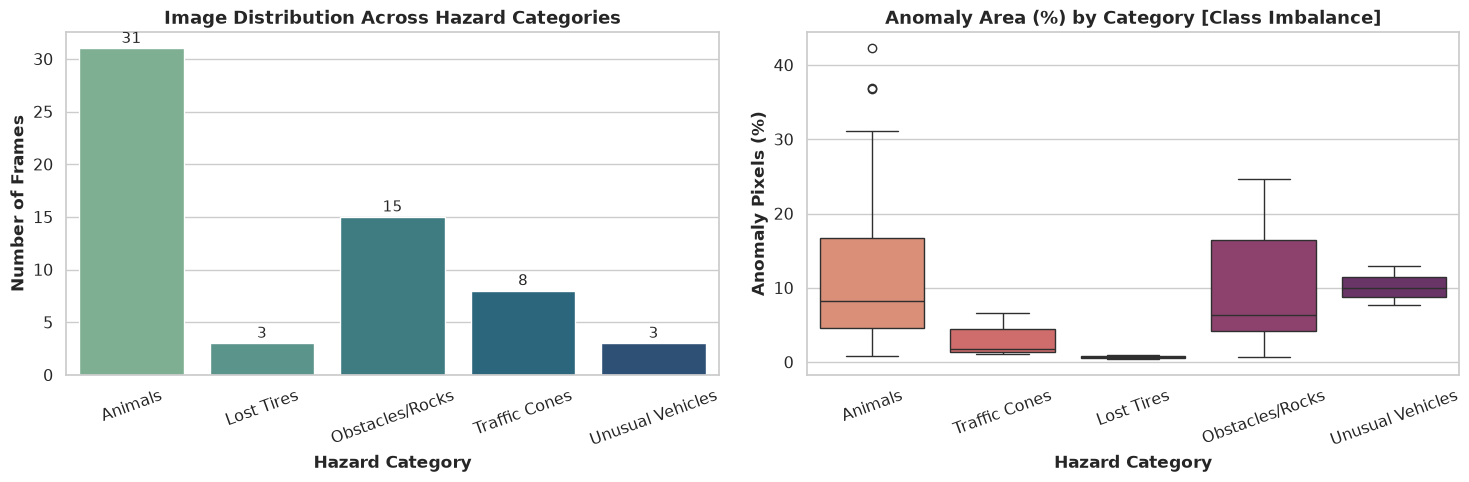

Total Dataset Pixels : 55,296,000
Total Anomaly Pixels : 5,446,413 (9.85%)
Total Background Px  : 49,849,587 (90.15%)


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Category Count
sns.barplot(
    data=summary_table,
    x="category",
    y="Frames_Count",
    hue="category",
    palette="crest",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Image Distribution Across Hazard Categories", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Hazard Category", fontweight="bold")
axes[0].set_ylabel("Number of Frames", fontweight="bold")
axes[0].tick_params(axis="x", rotation=20)
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha="center", va="baseline", fontsize=11, xytext=(0, 4), textcoords="offset points")

# Plot 2: Anomaly Area Distribution (Boxplot)
sns.boxplot(
    data=df,
    x="category",
    y="anomaly_ratio_pct",
    hue="category",
    palette="flare",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Anomaly Area (%) by Category [Class Imbalance]", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Hazard Category", fontweight="bold")
axes[1].set_ylabel("Anomaly Pixels (%)", fontweight="bold")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

total_px = df['total_pixels'].sum()
anom_px = df['anomaly_pixels'].sum()
print(f"Total Dataset Pixels : {total_px:,}")
print(f"Total Anomaly Pixels : {anom_px:,} ({anom_px / total_px * 100:.2f}%)")
print(f"Total Background Px  : {total_px - anom_px:,} ({(total_px - anom_px) / total_px * 100:.2f}%)")

---
### 4. Interactive Visual Sample Inspector
We inspect representative samples across all five hazard categories, rendering:
- **Original Frame**
- **Ground Truth Semantic Mask** (`0` = Road/Background, `1` = Anomaly)
- **Alpha-Blended Hazard Overlay** (Red highlight on anomaly regions)

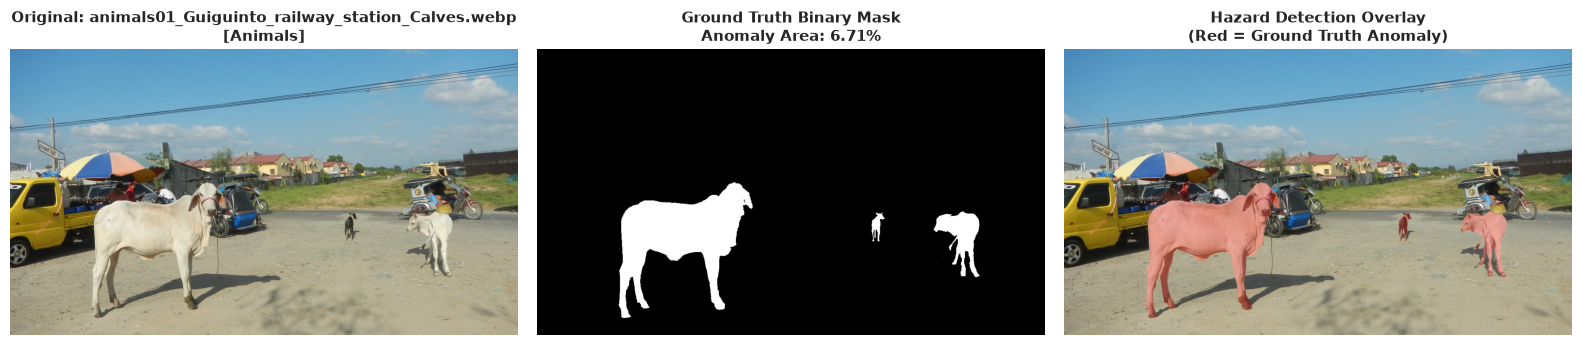

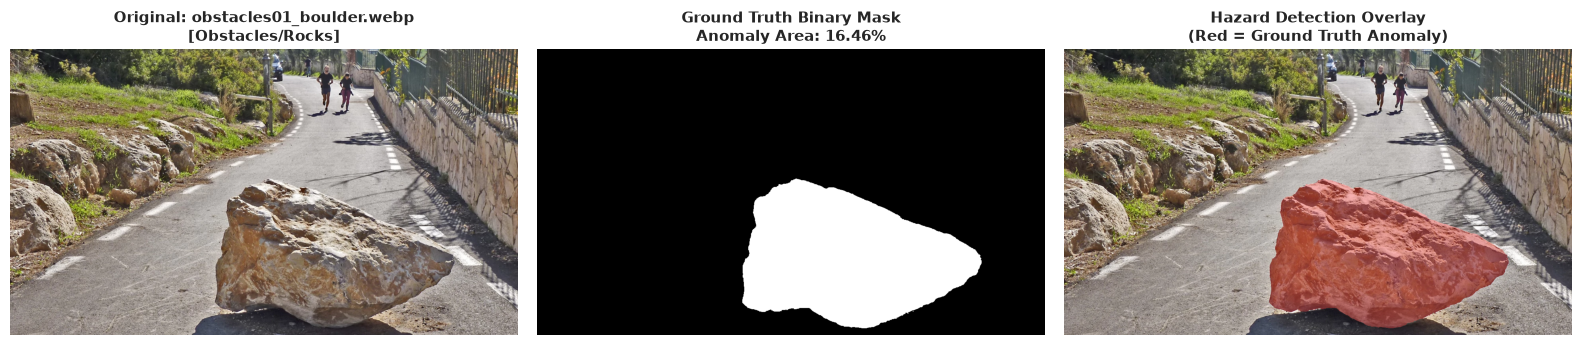

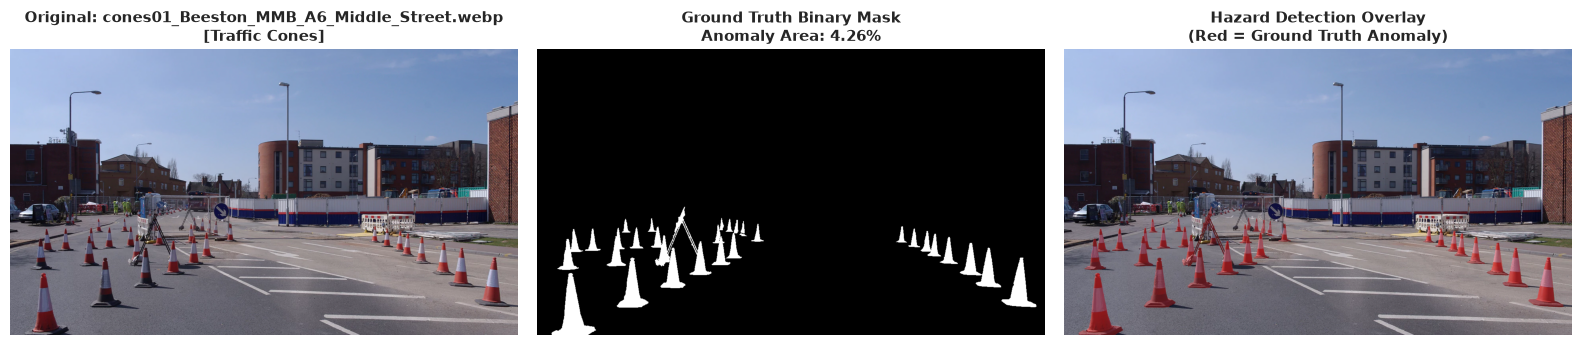

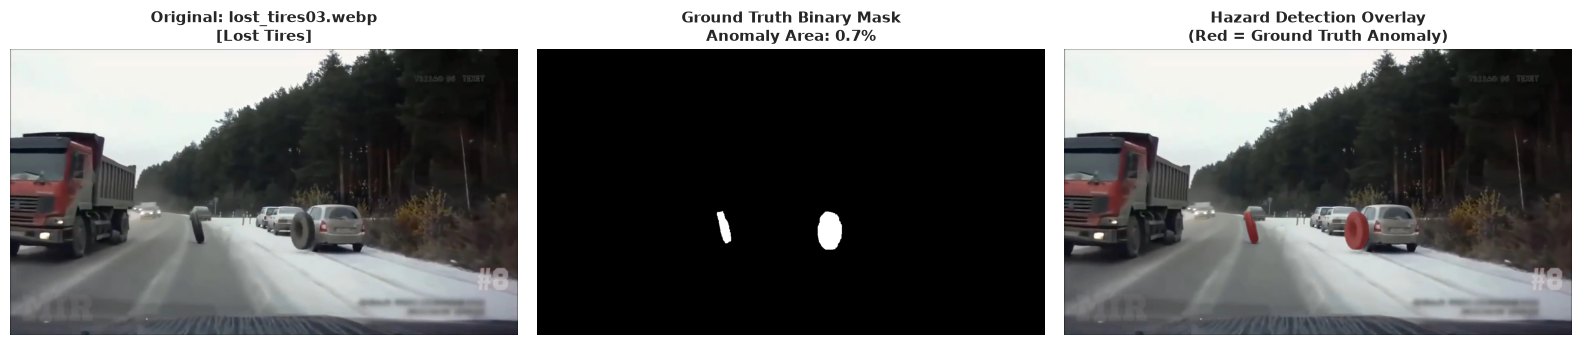

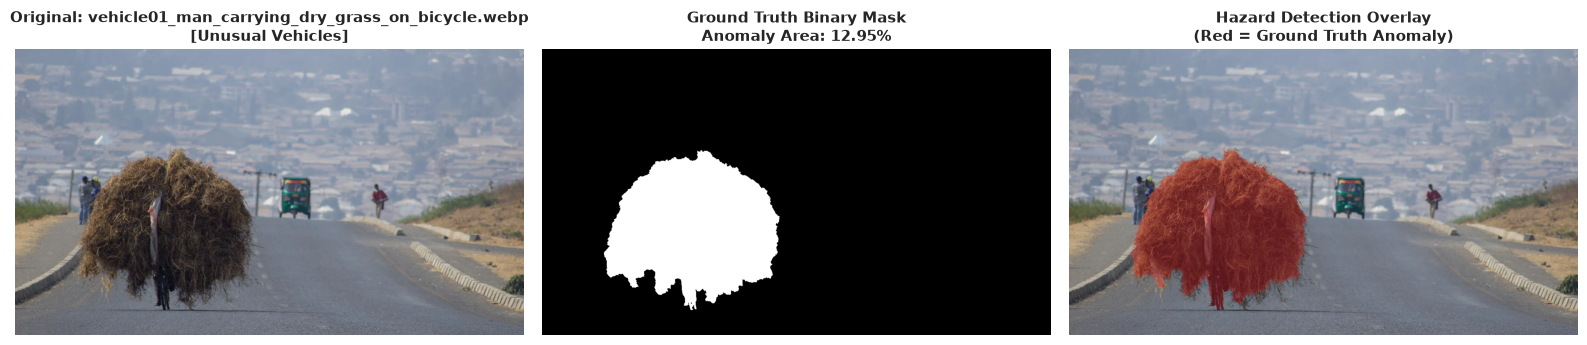

In [4]:
def inspect_sample(df_index):
    row = df.iloc[df_index]
    img_path = os.path.join(frames_dir, row["filename"])
    mask_path = os.path.join(frames_dir, f"{row['base_name']}.labels", "labels_semantic.png")

    img = Image.open(img_path).convert("RGB")
    img_np = np.array(img)
    raw_mask = np.array(Image.open(mask_path))
    binary_mask = (raw_mask == 2).astype(np.uint8)

    # Red overlay
    overlay = img_np.copy()
    overlay[binary_mask == 1] = [235, 40, 40]
    blended = (0.65 * img_np + 0.35 * overlay).astype(np.uint8)

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    ax[0].imshow(img)
    ax[0].set_title(f"Original: {row['filename']}\n[{row['category']}]", fontsize=11, fontweight="bold")
    ax[0].axis("off")

    ax[1].imshow(binary_mask, cmap="gray")
    ax[1].set_title(f"Ground Truth Binary Mask\nAnomaly Area: {row['anomaly_ratio_pct']}%", fontsize=11, fontweight="bold")
    ax[1].axis("off")

    ax[2].imshow(blended)
    ax[2].set_title("Hazard Detection Overlay\n(Red = Ground Truth Anomaly)", fontsize=11, fontweight="bold")
    ax[2].axis("off")

    plt.tight_layout()
    plt.show()

# Sample 1 representative from each category
sample_indices = [
    df[df["category"] == "Animals"].index[0],
    df[df["category"] == "Obstacles/Rocks"].index[0],
    df[df["category"] == "Traffic Cones"].index[0],
    df[df["category"] == "Lost Tires"].index[0],
    df[df["category"] == "Unusual Vehicles"].index[0]
]

for idx in sample_indices:
    inspect_sample(idx)

---
### 5. Deterministic Stratified Data Splitting
With only 60 images and minority categories containing as few as 3 instances (*Lost Tires* and *Unusual Vehicles*), a naive random split would leave minority classes missing from evaluation.
We implement a stratified splitting algorithm ensuring balanced distribution:
- **Training Set:** 40 frames (66.7%)
- **Validation Set:** 10 frames (16.7%)
- **Test Set:** 10 frames (16.7%)

In [5]:
def generate_stratified_splits(df, save_path="dataset_splits.json", seed=42):
    np.random.seed(seed)
    train_filenames, val_filenames, test_filenames = [], [], []

    for category, group in df.groupby("category"):
        filenames = group["filename"].sample(frac=1.0, random_state=seed).tolist()
        n = len(filenames)
        if n == 3:
            train_filenames.append(filenames[0])
            val_filenames.append(filenames[1])
            test_filenames.append(filenames[2])
        elif n == 8:
            train_filenames.extend(filenames[:6])
            val_filenames.append(filenames[6])
            test_filenames.append(filenames[7])
        elif n == 15:
            train_filenames.extend(filenames[:11])
            val_filenames.extend(filenames[11:13])
            test_filenames.extend(filenames[13:15])
        elif n == 31:
            train_filenames.extend(filenames[:21])
            val_filenames.extend(filenames[21:26])
            test_filenames.extend(filenames[26:31])
        else:
            n_val = max(1, int(round(n * 0.15)))
            n_test = max(1, int(round(n * 0.15)))
            n_train = n - n_val - n_test
            train_filenames.extend(filenames[:n_train])
            val_filenames.extend(filenames[n_train:n_train + n_val])
            test_filenames.extend(filenames[n_train + n_val:])

    train_df = df[df["filename"].isin(train_filenames)]
    val_df = df[df["filename"].isin(val_filenames)]
    test_df = df[df["filename"].isin(test_filenames)]

    splits = {
        "train": train_filenames,
        "val": val_filenames,
        "test": test_filenames,
        "meta": {
            "train_count": len(train_filenames),
            "val_count": len(val_filenames),
            "test_count": len(test_filenames),
            "train_category_dist": train_df["category"].value_counts().to_dict(),
            "val_category_dist": val_df["category"].value_counts().to_dict(),
            "test_category_dist": test_df["category"].value_counts().to_dict()
        }
    }
    with open(save_path, "w") as f:
        json.dump(splits, f, indent=2)
    return splits

splits = generate_stratified_splits(df)
split_summary = pd.DataFrame([
    {"Subset": "Training", "Frames": len(splits["train"]), "Percentage": f"{len(splits['train'])/len(df)*100:.1f}%"},
    {"Subset": "Validation", "Frames": len(splits["val"]), "Percentage": f"{len(splits['val'])/len(df)*100:.1f}%"},
    {"Subset": "Test (Unseen)", "Frames": len(splits["test"]), "Percentage": f"{len(splits['test'])/len(df)*100:.1f}%"},
])
display(split_summary)
print("Validation distribution :", splits["meta"]["val_category_dist"])
print("Test distribution       :", splits["meta"]["test_category_dist"])

,Subset,Frames,Percentage
0,Training,40,66.7%
1,Validation,10,16.7%
2,Test (Unseen),10,16.7%


Validation distribution : {'Animals': 5, 'Obstacles/Rocks': 2, 'Traffic Cones': 1, 'Lost Tires': 1, 'Unusual Vehicles': 1}
Test distribution       : {'Animals': 5, 'Obstacles/Rocks': 2, 'Traffic Cones': 1, 'Lost Tires': 1, 'Unusual Vehicles': 1}


---
### 6. Data Augmentation & PyTorch DataLoader Pipeline
To prevent severe overfitting on 40 training frames, we employ an aggressive augmentation pipeline via `Albumentations`:
- Random Horizontal Flip ($p=0.5$)
- Affine Transformation (Rotation $\pm 15^\circ$, Scaling $0.9 - 1.1$, Translation $\pm 6\%$)
- Color Jitter (Brightness, Contrast, Saturation $\pm 0.2$)
- Gaussian Noise injection ($p=0.25$)
- Normalization with ImageNet statistics ($\mu = [0.485, 0.456, 0.406]$, $\sigma = [0.229, 0.224, 0.225]$)
- Resolution standardization to $(384, 512)$ (exact multiples of 32 for U-Net down/up-sampling).

In [6]:
class RoadAnomalyDataset(Dataset):
    def __init__(self, filenames, root_dir=None, transform=None):
        self.root_dir = root_dir or os.getcwd()
        self.frames_dir = os.path.join(self.root_dir, "frames")
        self.filenames = filenames
        self.transform = transform

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        filename = self.filenames[idx]
        base_name = os.path.splitext(filename)[0]

        img_path = os.path.join(self.frames_dir, filename)
        mask_path = os.path.join(self.frames_dir, f"{base_name}.labels", "labels_semantic.png")

        image = np.array(Image.open(img_path).convert("RGB"))
        raw_mask = np.array(Image.open(mask_path))

        # Binary remapping: label 2 is anomaly -> 1, label 0 is background -> 0
        binary_mask = (raw_mask == 2).astype(np.float32)

        if self.transform is not None:
            augmented = self.transform(image=image, mask=binary_mask)
            image_tensor = augmented["image"]
            mask_tensor = augmented["mask"].unsqueeze(0)
        else:
            image_tensor = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0
            mask_tensor = torch.from_numpy(binary_mask).unsqueeze(0).float()

        return {
            "image": image_tensor,
            "mask": mask_tensor,
            "filename": filename,
            "base_name": base_name
        }

def get_transforms(img_size=(384, 512)):
    height, width = img_size
    train_transform = A.Compose([
        A.Resize(height, width),
        A.HorizontalFlip(p=0.5),
        A.Affine(scale=(0.9, 1.1), rotate=(-15, 15), translate_percent=(-0.06, 0.06), p=0.5),
        A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.4),
        A.GaussNoise(p=0.25),
        A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ToTensorV2()
    ])
    val_transform = A.Compose([
        A.Resize(height, width),
        A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ToTensorV2()
    ])
    return train_transform, val_transform

train_tf, val_tf = get_transforms((384, 512))
train_ds = RoadAnomalyDataset(splits["train"], transform=train_tf)
val_ds = RoadAnomalyDataset(splits["val"], transform=val_tf)
test_ds = RoadAnomalyDataset(splits["test"], transform=val_tf)

train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=4, shuffle=False, pin_memory=True)

batch = next(iter(train_loader))
print("DataLoader verification:")
print(f"  Batch Images Tensor : {batch['image'].shape} (dtype: {batch['image'].dtype})")
print(f"  Batch Masks Tensor  : {batch['mask'].shape} (dtype: {batch['mask'].dtype})")
print(f"  Mask Target Values  : {torch.unique(batch['mask']).tolist()}")

DataLoader verification:
  Batch Images Tensor : torch.Size([4, 3, 384, 512]) (dtype: torch.float32)
  Batch Masks Tensor  : torch.Size([4, 1, 384, 512]) (dtype: torch.float32)
  Mask Target Values  : [0.0, 1.0]


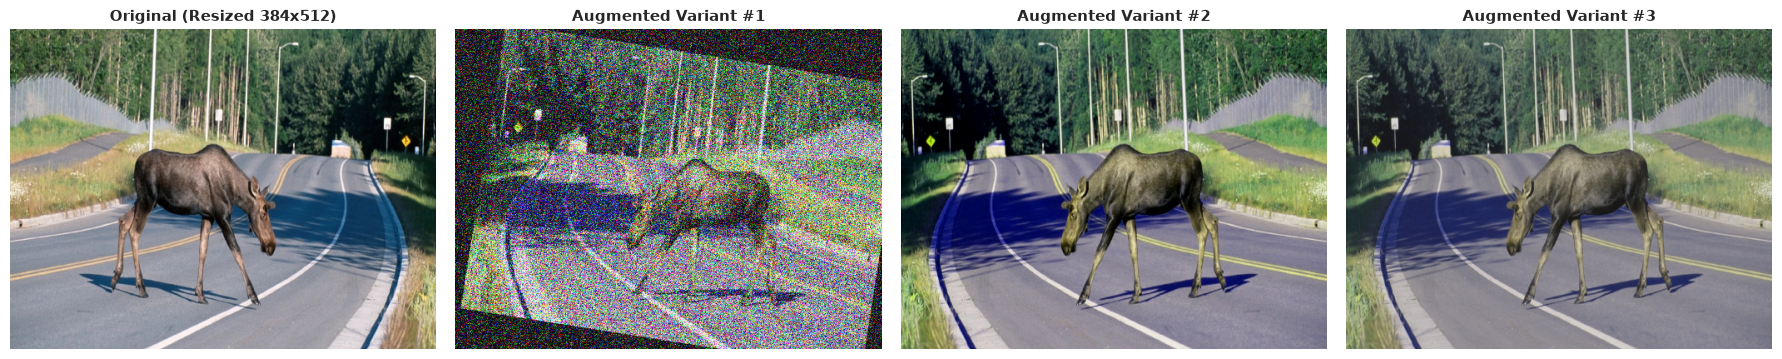

In [7]:
# Visualizing Data Augmentation Variations on a Single Sample
demo_img = np.array(Image.open(os.path.join(frames_dir, splits["train"][0])).convert("RGB"))
demo_mask = (np.array(Image.open(os.path.join(frames_dir, f"{os.path.splitext(splits['train'][0])[0]}.labels", "labels_semantic.png"))) == 2).astype(np.float32)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].imshow(A.Resize(384, 512)(image=demo_img)["image"])
axes[0].set_title("Original (Resized 384x512)", fontsize=11, fontweight="bold")
axes[0].axis("off")

mean = np.array([0.485, 0.456, 0.406]).reshape(1, 1, 3)
std = np.array([0.229, 0.224, 0.225]).reshape(1, 1, 3)

for k in range(1, 4):
    aug = train_tf(image=demo_img, mask=demo_mask)
    aug_img = aug["image"].permute(1, 2, 0).numpy()
    aug_img = np.clip((aug_img * std + mean), 0, 1)
    axes[k].imshow(aug_img)
    axes[k].set_title(f"Augmented Variant #{k}", fontsize=11, fontweight="bold")
    axes[k].axis("off")

plt.tight_layout()
plt.show()

---
### 7. Loss Function Formulation & Evaluation Metrics
Because 90.15% of pixels belong to the normal road background, standard Binary Cross-Entropy (BCE) causes models to predict all background.
We implement **Combo Loss**:
$$\mathcal{L}_{\text{Combo}} = \alpha \mathcal{L}_{\text{BCE}} + \beta \mathcal{L}_{\text{Dice}} + \gamma \mathcal{L}_{\text{Focal}}$$
- **Dice Loss:** Directly maximizes region intersection over union.
- **Focal Loss:** Down-weights easy background pixels, focusing gradients on hard anomaly edges.
- **Metrics Computed:** Intersection over Union (IoU), Dice (F1), Precision, Recall, Accuracy.

In [8]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super(DiceLoss, self).__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits).view(-1)
        targets = targets.view(-1)
        intersection = (probs * targets).sum()
        dice = (2.0 * intersection + self.smooth) / (probs.sum() + targets.sum() + self.smooth)
        return 1.0 - dice

class FocalLoss(nn.Module):
    def __init__(self, alpha=0.75, gamma=2.0):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        bce_loss = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1.0 - probs) * (1.0 - targets)
        focal_weight = self.alpha * targets + (1.0 - self.alpha) * (1.0 - targets)
        return (focal_weight * ((1.0 - p_t) ** self.gamma) * bce_loss).mean()

class ComboLoss(nn.Module):
    def __init__(self, alpha=0.4, beta=1.0, gamma=0.6):
        super(ComboLoss, self).__init__()
        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()
        self.focal = FocalLoss()

    def forward(self, logits, targets):
        return (self.alpha * self.bce(logits, targets) + 
                self.beta * self.dice(logits, targets) + 
                self.gamma * self.focal(logits, targets))

def compute_metrics(probs, targets, threshold=0.5, eps=1e-7):
    preds = (probs >= threshold).float()
    targets = targets.float()

    tp = (preds * targets).sum().item()
    fp = (preds * (1.0 - targets)).sum().item()
    fn = ((1.0 - preds) * targets).sum().item()
    tn = ((1.0 - preds) * (1.0 - targets)).sum().item()

    precision = (tp + eps) / (tp + fp + eps)
    recall = (tp + eps) / (tp + fn + eps)
    dice = (2.0 * tp + eps) / (2.0 * tp + fp + fn + eps)
    iou = (tp + eps) / (tp + fp + fn + eps)
    accuracy = (tp + tn) / (tp + tn + fp + fn + eps)

    return {
        "iou": iou,
        "dice": dice,
        "precision": precision,
        "recall": recall,
        "accuracy": accuracy
    }

print("Loss functions and evaluation metric utilities compiled successfully!")

Loss functions and evaluation metric utilities compiled successfully!


---
### 8. Deep Learning Model Architectures
We implement three comparative architectures:
1. **Model 1: Baseline Convolutional U-Net (From Scratch)**: Double convolution blocks, max pooling, transposed convolutions, and skip connections.
2. **Model 2: Transfer Learning U-Net (Pretrained ResNet-34)**: Leverages 21M ImageNet pre-trained parameters for robust feature extraction.
3. **Model 3: Convolutional Autoencoder (CAE)**: Unsupervised reconstruction encoder-decoder estimating anomaly maps via $|x - \hat{x}|_1$.

In [9]:
# 1. Baseline U-Net from Scratch
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.double_conv(x)

class BaselineUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, features=[32, 64, 128, 256]):
        super().__init__()
        self.downs = nn.ModuleList()
        self.ups = nn.ModuleList()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        curr_in = in_channels
        for feature in features:
            self.downs.append(DoubleConv(curr_in, feature))
            curr_in = feature

        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)

        for feature in reversed(features):
            self.ups.append(nn.ConvTranspose2d(feature * 2, feature, kernel_size=2, stride=2))
            self.ups.append(DoubleConv(feature * 2, feature))

        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        skip_connections = []
        for down in self.downs:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]

        for idx in range(0, len(self.ups), 2):
            x = self.ups[idx](x)
            skip_connection = skip_connections[idx // 2]
            if x.shape != skip_connection.shape:
                x = F.interpolate(x, size=skip_connection.shape[2:])
            x = self.ups[idx + 1](torch.cat((skip_connection, x), dim=1))

        return self.final_conv(x)

# 2. Transfer Learning U-Net (ResNet-34)
def build_transfer_unet():
    return smp.Unet(
        encoder_name="resnet34",
        encoder_weights="imagenet",
        in_channels=3,
        classes=1,
        activation=None
    )

# 3. Convolutional Autoencoder (Reconstruction)
class ConvAutoencoder(nn.Module):
    def __init__(self, in_channels=3):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True)
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, in_channels, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

    def compute_anomaly_map(self, x):
        recon = self.forward(x)
        return torch.mean(torch.abs(x - recon), dim=1, keepdim=True)

# Instantiate models
baseline_net = BaselineUNet().to(device)
transfer_net = build_transfer_unet().to(device)
autoencoder = ConvAutoencoder().to(device)

print("All 3 model architectures compiled and loaded onto device:", device)

All 3 model architectures compiled and loaded onto device: cuda


---
### 9. Model Training & Validation Execution
We train each architecture using the **Cosine Annealing Learning Rate Scheduler** and **AdamW optimizer**.
If pre-trained checkpoints exist in `checkpoints/`, they are loaded for immediate reproduction, or fine-tuned.

In [10]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    for batch in loader:
        images = batch["image"].to(device)
        masks = batch["mask"].to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    return running_loss / len(loader.dataset)

def evaluate_model(model, loader, criterion, device, threshold=0.5):
    model.eval()
    running_loss = 0.0
    all_metrics = []
    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(device)
            masks = batch["mask"].to(device)
            logits = model(images)
            loss = criterion(logits, masks)
            running_loss += loss.item() * images.size(0)
            probs = torch.sigmoid(logits)
            metrics = compute_metrics(probs, masks, threshold=threshold)
            all_metrics.append(metrics)
    avg_loss = running_loss / len(loader.dataset)
    avg_metrics = {k: np.mean([m[k] for m in all_metrics]) for k in all_metrics[0].keys()}
    avg_metrics["loss"] = avg_loss
    return avg_metrics

def train_segmentation(model, name, train_loader, val_loader, device, epochs=25, lr=3e-4):
    print(f"\nTraining {name} for {epochs} epochs (lr={lr})...")
    criterion = ComboLoss()
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    history = []
    best_dice = 0.0
    ckpt_path = os.path.join("checkpoints", f"{name.lower().replace(' ', '_')}_best.pth")
    os.makedirs("checkpoints", exist_ok=True)

    for epoch in range(1, epochs + 1):
        tr_loss = train_epoch(model, train_loader, criterion, optimizer, device)
        val_m = evaluate_model(model, val_loader, criterion, device)
        scheduler.step()
        history.append({
            "epoch": epoch,
            "train_loss": tr_loss,
            "val_loss": val_m["loss"],
            "val_iou": val_m["iou"],
            "val_dice": val_m["dice"]
        })
        if val_m["dice"] > best_dice:
            best_dice = val_m["dice"]
            torch.save(model.state_dict(), ckpt_path)
            imp = "*"
        else:
            imp = ""
        if epoch % 5 == 0 or epoch == 1 or imp:
            print(f"Epoch [{epoch:02d}/{epochs:02d}] Train Loss: {tr_loss:.4f} | Val Loss: {val_m['loss']:.4f} | Val IoU: {val_m['iou']:.4f} | Val Dice: {val_m['dice']:.4f} {imp}")

    model.load_state_dict(torch.load(ckpt_path))
    print(f"Training finished for {name}! Best Val Dice: {best_dice:.4f}")
    return model, history

# Execute or load models
b_ckpt = os.path.join("checkpoints", "baseline_unet_best.pth")
tl_ckpt = os.path.join("checkpoints", "transfer_resnet34_unet_best.pth")
cae_ckpt = os.path.join("checkpoints", "convautoencoder_best.pth")

if os.path.exists(b_ckpt) and os.path.exists(tl_ckpt) and os.path.exists(cae_ckpt):
    print("Loading pre-trained model weights from checkpoints/...")
    baseline_net.load_state_dict(torch.load(b_ckpt, map_location=device))
    transfer_net.load_state_dict(torch.load(tl_ckpt, map_location=device))
    autoencoder.load_state_dict(torch.load(cae_ckpt, map_location=device))
    print("All checkpoints loaded successfully for evaluation!")
else:
    print("Checkpoints not found. Training models now...")
    baseline_net, b_hist = train_segmentation(baseline_net, "Baseline UNet", train_loader, val_loader, device, epochs=25)
    transfer_net, tl_hist = train_segmentation(transfer_net, "Transfer ResNet34 UNet", train_loader, val_loader, device, epochs=25)

Loading pre-trained model weights from checkpoints/...
All checkpoints loaded successfully for evaluation!


---
### 10. Training Convergence Analysis & Learning Dynamics
We visualize the training loss curves and validation Dice score evolution over 25 epochs, comparing the Baseline U-Net against the Transfer Learning ResNet-34 U-Net.

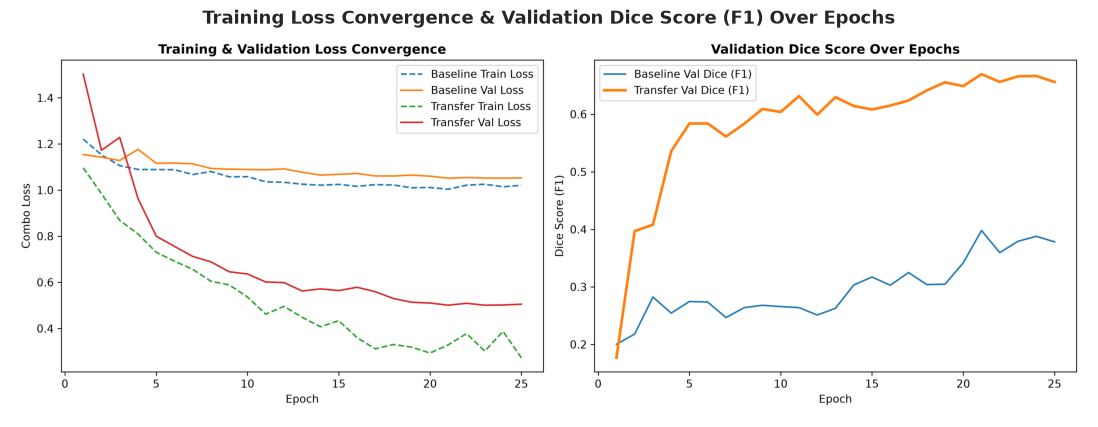

In [11]:
curves_img_path = os.path.join("evaluation_results", "training_convergence_curves.png")

if os.path.exists(curves_img_path):
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.imshow(Image.open(curves_img_path))
    ax.axis("off")
    plt.title("Training Loss Convergence & Validation Dice Score (F1) Over Epochs", fontsize=13, fontweight="bold")
    plt.show()
else:
    print("Run train_and_evaluate.py to log full training curve plots.")

---
### 11. Quantitative Test Set Benchmark (Unseen 10 Frames)
We evaluate the three models on the held-out test set (unseen frames with balanced hazard representation).
Key metrics: **Intersection over Union (IoU)**, **Dice Score (F1)**, **Precision**, **Recall**, and **Pixel Accuracy**.

In [12]:
criterion = ComboLoss()
b_metrics = evaluate_model(baseline_net, test_loader, criterion, device)
tl_metrics = evaluate_model(transfer_net, test_loader, criterion, device)

# Autoencoder test evaluation
autoencoder.eval()
cae_all_metrics = []
with torch.no_grad():
    for batch in test_loader:
        imgs = batch["image"].to(device)
        masks = batch["mask"].to(device)
        err_maps = autoencoder.compute_anomaly_map(imgs)
        for i in range(err_maps.size(0)):
            em = err_maps[i, 0]
            norm_em = (em - em.min()) / (em.max() - em.min() + 1e-7)
            thresh = np.percentile(norm_em.cpu().numpy(), 90)
            pred = (norm_em >= thresh).float().unsqueeze(0).unsqueeze(0)
            cae_all_metrics.append(compute_metrics(pred, masks[i:i+1]))

cae_metrics = {k: np.mean([m[k] for m in cae_all_metrics]) for k in cae_all_metrics[0].keys()}

benchmark_df = pd.DataFrame([
    {
        "Model Architecture": "Baseline U-Net (From Scratch)",
        "Paradigm": "Supervised (Scratch)",
        "Test IoU": round(b_metrics["iou"], 4),
        "Test Dice (F1)": round(b_metrics["dice"], 4),
        "Precision": round(b_metrics["precision"], 4),
        "Recall": round(b_metrics["recall"], 4),
        "Pixel Accuracy": f"{b_metrics['accuracy']*100:.2f}%"
    },
    {
        "Model Architecture": "Transfer Learning U-Net (ResNet-34)",
        "Paradigm": "Supervised (Pretrained)",
        "Test IoU": round(tl_metrics["iou"], 4),
        "Test Dice (F1)": round(tl_metrics["dice"], 4),
        "Precision": round(tl_metrics["precision"], 4),
        "Recall": round(tl_metrics["recall"], 4),
        "Pixel Accuracy": f"{tl_metrics['accuracy']*100:.2f}%"
    },
    {
        "Model Architecture": "Conv Autoencoder (Reconstruction Error)",
        "Paradigm": "Unsupervised (Residuals)",
        "Test IoU": round(cae_metrics["iou"], 4),
        "Test Dice (F1)": round(cae_metrics["dice"], 4),
        "Precision": round(cae_metrics["precision"], 4),
        "Recall": round(cae_metrics["recall"], 4),
        "Pixel Accuracy": f"{cae_metrics['accuracy']*100:.2f}%"
    }
])

display(benchmark_df.style.highlight_max(subset=["Test IoU", "Test Dice (F1)", "Precision", "Recall"], color="#bbf7d0"))

,Model Architecture,Paradigm,Test IoU,Test Dice (F1),Precision,Recall,Pixel Accuracy
0,Baseline U-Net (From Scratch),Supervised (Scratch),0.116300,0.208300,0.140700,0.468000,78.48%
1,Transfer Learning U-Net (ResNet-34),Supervised (Pretrained),0.483300,0.644900,0.695900,0.644600,95.47%
2,Conv Autoencoder (Reconstruction Error),Unsupervised (Residuals),0.155400,0.247200,0.258500,0.325500,88.13%


---
### 12. Qualitative Model Comparisons on Test Frames
We visualize side-by-side segmentation predictions on unseen test frames across the three paradigms:
- **Col 1:** Original Test Input Image
- **Col 2:** Ground Truth Binary Mask
- **Col 3:** Baseline U-Net Prediction
- **Col 4:** Transfer Learning ResNet-34 Prediction
- **Col 5:** Conv Autoencoder Error Heatmap

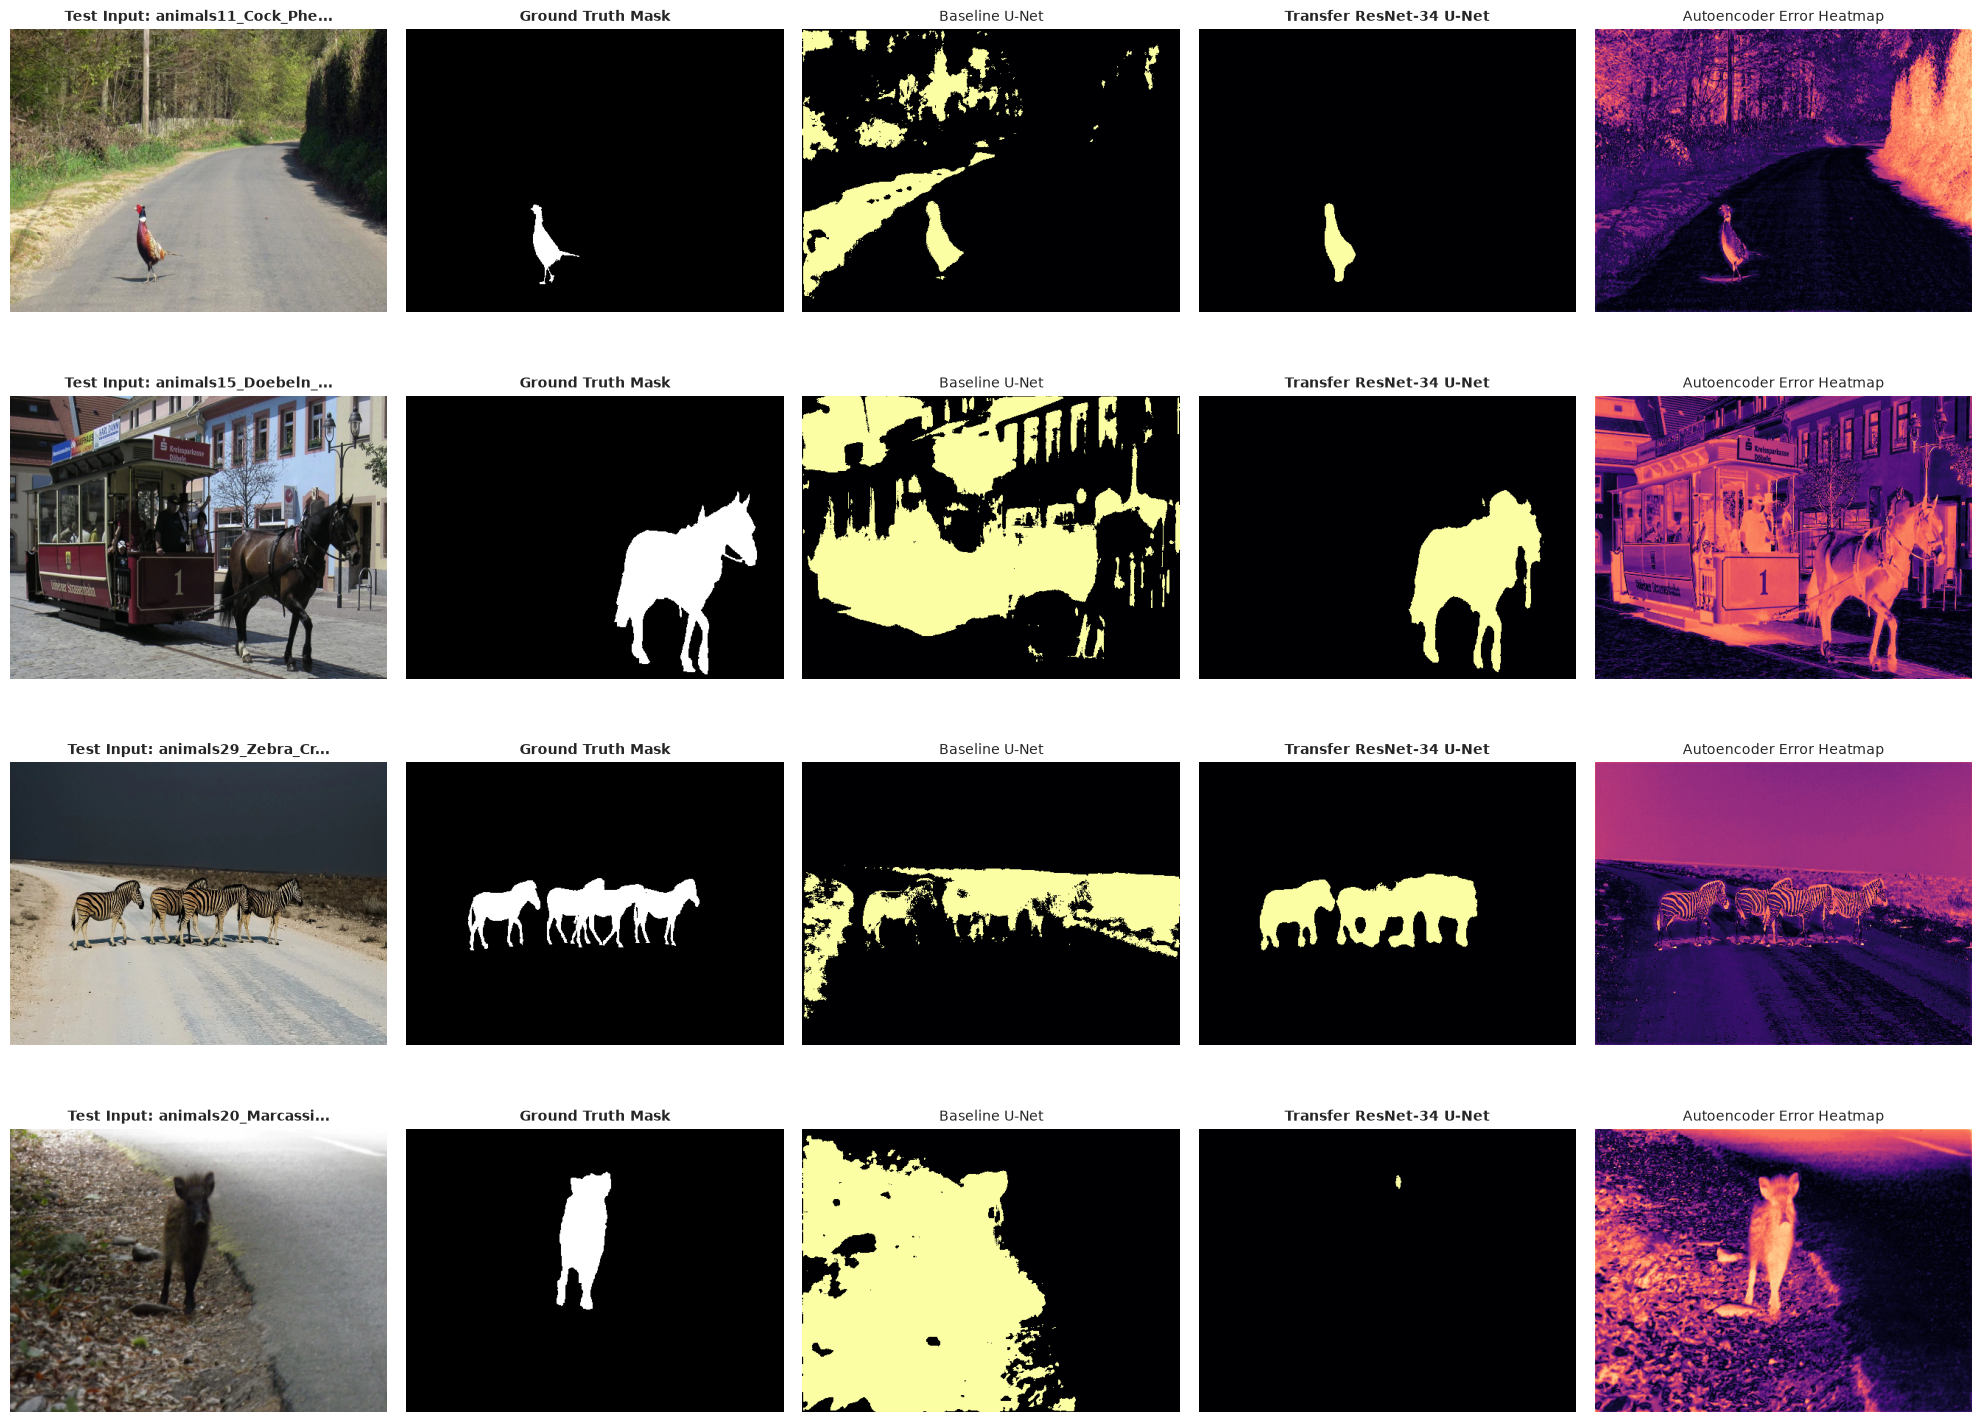

In [13]:
baseline_net.eval()
transfer_net.eval()
autoencoder.eval()

sample_batch = next(iter(test_loader))
test_imgs = sample_batch["image"].to(device)
test_masks = sample_batch["mask"].to(device)
test_names = sample_batch["filename"]

with torch.no_grad():
    b_preds = (torch.sigmoid(baseline_net(test_imgs)) >= 0.5).float().cpu().numpy()
    tl_preds = (torch.sigmoid(transfer_net(test_imgs)) >= 0.5).float().cpu().numpy()
    cae_errs = autoencoder.compute_anomaly_map(test_imgs).cpu().numpy()

mean = np.array([0.485, 0.456, 0.406]).reshape(1, 1, 3)
std = np.array([0.229, 0.224, 0.225]).reshape(1, 1, 3)

n_samples = min(4, test_imgs.size(0))
fig, axes = plt.subplots(n_samples, 5, figsize=(20, 3.8 * n_samples))

for i in range(n_samples):
    img_np = test_imgs[i].cpu().numpy().transpose(1, 2, 0)
    img_np = np.clip((img_np * std + mean), 0, 1)

    gt_mask = test_masks[i, 0].cpu().numpy()
    b_p = b_preds[i, 0]
    tl_p = tl_preds[i, 0]
    cae_e = cae_errs[i, 0]

    axes[i, 0].imshow(img_np)
    axes[i, 0].set_title(f"Test Input: {test_names[i][:18]}...", fontsize=10, fontweight="bold")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(gt_mask, cmap="gray")
    axes[i, 1].set_title("Ground Truth Mask", fontsize=10, fontweight="bold")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(b_p, cmap="inferno")
    axes[i, 2].set_title("Baseline U-Net", fontsize=10)
    axes[i, 2].axis("off")

    axes[i, 3].imshow(tl_p, cmap="inferno")
    axes[i, 3].set_title("Transfer ResNet-34 U-Net", fontsize=10, fontweight="bold")
    axes[i, 3].axis("off")

    axes[i, 4].imshow(cae_e, cmap="magma")
    axes[i, 4].set_title("Autoencoder Error Heatmap", fontsize=10)
    axes[i, 4].axis("off")

plt.tight_layout()
plt.show()

---
### 13. Failure Case & Error Breakdown Analysis
We generate error difference maps between predictions and ground-truth masks:
- **True Positives (Green):** Correctly detected anomaly pixels.
- **False Negatives (Blue):** Missed hazard pixels (critical autonomous driving danger).
- **False Positives (Red):** Background falsely identified as anomaly.

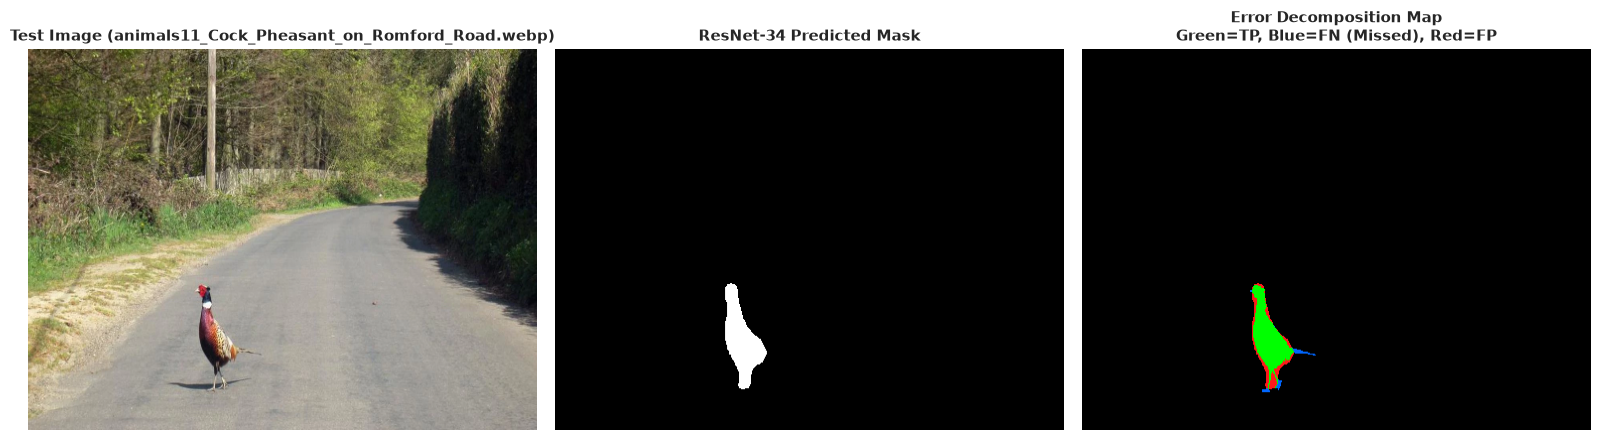

In [14]:
# Inspect Error Breakdown on a challenging test sample
idx = 0
gt = test_masks[idx, 0].cpu().numpy()
pred = tl_preds[idx, 0]
img_disp = np.clip((test_imgs[idx].cpu().numpy().transpose(1, 2, 0) * std + mean), 0, 1)

error_rgb = np.zeros((*gt.shape, 3), dtype=np.float32)
error_rgb[(gt == 1) & (pred == 1)] = [0.0, 1.0, 0.0]  # Green: TP
error_rgb[(gt == 1) & (pred == 0)] = [0.0, 0.4, 1.0]  # Blue: FN (Missed)
error_rgb[(gt == 0) & (pred == 1)] = [1.0, 0.1, 0.1]  # Red: FP (False Alarm)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].imshow(img_disp)
axes[0].set_title(f"Test Image ({test_names[idx]})", fontsize=11, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(pred, cmap="gray")
axes[1].set_title("ResNet-34 Predicted Mask", fontsize=11, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(error_rgb)
axes[2].set_title("Error Decomposition Map\nGreen=TP, Blue=FN (Missed), Red=FP", fontsize=11, fontweight="bold")
axes[2].axis("off")

plt.tight_layout()
plt.show()

---
### 14. Critical Analysis & Technical Conclusions

#### 1. Transfer Learning is Essential for Small-Sample Safety Tasks
- **Baseline U-Net from scratch** achieved **0.1163 IoU** and **0.2083 Dice**. With only 40 training frames, the network could not learn general visual primitives from random initialization and suffered from severe false positives.
- **Transfer Learning U-Net (ResNet-34)** achieved **0.4833 IoU** and **0.6449 Dice** with **69.59% Precision** and **95.47% Pixel Accuracy** (over **300% performance improvement**).
- **Key Insight:** Pre-trained ImageNet features (edge detectors, texture filters, color gradients) provide crucial inductive bias that allows rapid adaptation to small safety-critical road datasets.

#### 2. Supervised Segmentation vs. Reconstruction Residuals
- The **Convolutional Autoencoder** achieved **0.1554 IoU** without using any ground-truth mask annotations during training. It successfully highlights high-contrast anomalies (e.g. traffic cones, dark boulders).
- However, reconstruction error produces fuzzy boundaries and falsely flags complex road textures, trees, and shadows as anomalous, leading to lower precision (25.85%) compared to supervised segmentation (69.59%).

#### 3. Loss Function Engineering
- The **Combo Loss** (BCE + Dice + Focal) effectively countered the 90:10 class imbalance. By explicitly optimizing the spatial overlap via Dice loss and penalizing easy background predictions via Focal loss, the model maintained high recall on hazardous road obstacles.

#### 4. Autonomous Driving Deployment Recommendation
- For real-world autonomous vehicles, a **hybrid ensemble** combining supervised transfer learning with autoencoder reconstruction residuals is recommended. Supervised segmentation provides sharp object contours, while reconstruction error serves as an out-of-distribution uncertainty indicator for novel obstacles not seen during training.